### 1. Pre-requisitos

In [ ]:
!pip install --only-binary=:all: spacy==3.8.18 networkx==3.5 scipy==1.16.3 gensim==4.4.0 huggingface_hub fsspec
!python -m spacy download es_core_news_md


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 7.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 27.8 MB/s  0:00:01
  Attempting uninstall: networkx
    Found existing installation: networkx 3.7
    Uninstalling networkx-3.7:
      Successfully uninstalled networkx-3.7
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [gensim]
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 MB 51.6 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import os
import re
import time
import unicodedata
import shutil
import zlib

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import spacy

from IPython.display import display
from gensim.models import Word2Vec
from scipy.sparse.csgraph import dijkstra
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

%matplotlib inline

# cargar spacy, desactivamos análisis sintáctico y reconocimiento de entidades
nlp = spacy.load("es_core_news_md", disable=["parser", "ner"])

# configuraciones para los experimentos
SEMILLA = 1950
ALPHA = 0.85
N_PRUEBA = 1000  # muestra fija para la final
MAX_DESARROLLO = 1000  # muestra fija para comparar modelos
CARPETA_SALIDA = "/content/gdrive/MyDrive/Proyecto2/salidas_proyecto2_limpio/desarrollo_1000"


### 2. Cargar y preparar los datasets

In [ ]:
#seleccionar que definiciones si vamos a usar

def seleccionar_definiciones(tabla):
    texto = tabla["definition"].astype("string")

    # palabra o el texto vacíos
    vacia = (
        tabla["word"].astype("string").str.strip().eq("").fillna(True)
        | texto.isna()
        | texto.str.strip().eq("").fillna(True)
    )

    # una conjugación
    conjugacion = tabla["classification"].fillna("").str.strip().str.casefold().eq("conjugación")

    # "Forma del/de … femenino/masculino/plural/singular"
    patron_forma = (
        r"^\s*forma\s+(?:(?:del?|de la|de los|de las)\s+)?"
        r"(?:femenin[oa]|masculin[oa]|plural|singular)\b"
    )
    forma = texto.str.contains(patron_forma, case=False, regex=True, na=False)

    # solo un encabezado
    encabezado = texto.str.fullmatch(
        r"\s*(?:nota de uso|uso|ámbito|etimología|sinónimos|antónimos|ejemplos?)\s*[:：]\s*[.\s]*",
        case=False, na=False,
    )

    # asignar el motivo de "rechazo"
    # si no hay motivo, se queda en
    motivo = np.select(
        [vacia, conjugacion, forma, encabezado],
        ["registro_vacio", "conjugacion", "glosa_de_forma", "encabezado_sin_definicion"],
        default="",
    )

    excluidas = tabla.loc[motivo != ""].copy()
    excluidas["motivo"] = motivo[motivo != ""]

    validas = tabla.loc[motivo == ""].copy()
    return validas, excluidas


In [ ]:
# conectar drive, y cargar NALC
from google.colab import drive

drive.mount("/content/gdrive")

directorio_csv = "/content/gdrive/MyDrive/Proyecto2/nalc_asociaciones.csv"

# versión de Wiktionary
REVISION_WIKTIONARY = "492b908dcc7ea201b64cb24b2d839db08385fa1c"
FUENTE_DEFINICIONES = f"hf://datasets/carloscapote/es.wiktionary.org@{REVISION_WIKTIONARY}/train.jsonl"

# copia local en drive, (la primera vez se crea, luego la leen directamente)
CACHE_DEFINICIONES = f"/content/gdrive/MyDrive/Proyecto2/cache/wiktionary_es_{REVISION_WIKTIONARY[:8]}.jsonl"


import os
import shutil
import fsspec
os.makedirs(os.path.dirname(CACHE_DEFINICIONES), exist_ok=True)

# si no existe, descargamos la versión
if not os.path.exists(CACHE_DEFINICIONES):
    with fsspec.open(FUENTE_DEFINICIONES, "rb") as origen, open(CACHE_DEFINICIONES + ".part", "wb") as destino:
        shutil.copyfileobj(origen, destino)
    os.replace(CACHE_DEFINICIONES + ".part", CACHE_DEFINICIONES)

FUENTE_DEFINICIONES = CACHE_DEFINICIONES

# leer las 2 tablas
asociaciones_originales = pd.read_csv(
    directorio_csv,
    encoding="utf-8-sig",  # evita cambio del nombre de la primera columna
    dtype={"CUE": "string", "TARGET": "string"},  # mantener palabras como texto.
)
definiciones_originales = pd.read_json(FUENTE_DEFINICIONES, lines=True)
print("Definiciones leídas desde:", FUENTE_DEFINICIONES)

# guardar las palabras originales (antes de normalizar)
asociaciones_originales["CUE_original"] = asociaciones_originales["CUE"]
asociaciones_originales["TARGET_original"] = asociaciones_originales["TARGET"]
definiciones_originales["word_original"] = definiciones_originales["word"]

# asignar un identificador a cada fila del Wiktionary
definiciones_originales["id"] = [f"wik_{i:07d}" for i in range(len(definiciones_originales))]
definiciones_originales["fuente"] = FUENTE_DEFINICIONES

# aplicar los criterios de selección
definiciones_base, excluidas_formas = seleccionar_definiciones(definiciones_originales)

print("Asociaciones originales:", len(asociaciones_originales))
print("Definiciones originales:", len(definiciones_originales))
print("Definiciones seleccionadas:", len(definiciones_base))
display(excluidas_formas["motivo"].value_counts().to_frame("filas"))
display(definiciones_base[["word_original", "classification", "definition"]].head(3))


Mounted at /content/gdrive
Definiciones leídas desde: /content/gdrive/MyDrive/Proyecto2/cache/wiktionary_es_492b908d.jsonl
Asociaciones originales: 90882
Definiciones originales: 873990
Definiciones seleccionadas: 101170


,filas
motivo,
conjugacion,742795
glosa_de_forma,30019
encabezado_sin_definicion,6


,word_original,classification,definition
0,aabam,sustantivo masculino,Nombre que los alquimistas daban al plomo.
1,aaban,sustantivo masculino,Nombre que los alquimistas daban al plomo.
2,aaça,sustantivo femenino,Lanza.


### 3. Normalizar

In [ ]:
# minusculas, unificar Unicode, y cambia espacios por _
def normalizar_superficie(texto):
    texto = unicodedata.normalize("NFC", str(texto)).strip().lower()
    return re.sub(r"\s+", "_", texto)

# normaliza columna completa
def normalizar_columna(columna, modelo, cache):
    valores = columna.astype("string")

    # buscar solo textos que todavía no están en la caché
    pendientes = [t for t in valores.dropna().unique() if t not in cache]

    # nlp.pipe procesa muchos textos juntos
    docs = modelo.pipe((t.replace("_", " ") for t in pendientes), batch_size=256)

    for original, doc in tqdm(zip(pendientes, docs), total=len(pendientes), desc=f"Normalizar {columna.name}"):
        # usar el lema de cada palabra, descartar signos y numeros
        cache[original] = "_".join(
            normalizar_superficie(t.lemma_ or t.text) for t in doc if t.is_alpha
        )

    # reemplazar cada valor por su versión normalizada, tomando en cuenta la caché
    return valores.map(cache)


In [ ]:
# caché compartida, CUE, TARGET y word usan mismos resultados
cache_normalizacion = {}

asociaciones_normalizadas = asociaciones_originales.copy()
for columna in ("CUE", "TARGET"):
    asociaciones_normalizadas[columna] = normalizar_columna(
        asociaciones_normalizadas[columna], nlp, cache_normalizacion
    )

definiciones_normalizadas = definiciones_base.copy()
definiciones_normalizadas["word"] = normalizar_columna(
    definiciones_normalizadas["word"], nlp, cache_normalizacion
)

display(asociaciones_normalizadas[["CUE_original", "CUE", "TARGET_original", "TARGET", "FSG"]].head(3))


Normalizar CUE:   0%|          | 0/6489 [00:00<?, ?it/s]

Normalizar TARGET:   0%|          | 0/7670 [00:00<?, ?it/s]

Normalizar word:   0%|          | 0/44391 [00:00<?, ?it/s]

,CUE_original,CUE,TARGET_original,TARGET,FSG
0,a,a,b,b,0.30
1,a,a,letra,letra,0.13
2,a,a,ante,ante,0.12


### 4. Construir el grafo dirigido

In [ ]:
# construir grafo dirigido, devuele filas que no se incluyeron

def construir_grafo(tabla):
    tabla = tabla.copy()

    # comprobar que FSG sea un número entre 0 y 1
    tabla["FSG"] = pd.to_numeric(tabla["FSG"], errors="raise")
    if not (np.isfinite(tabla["FSG"]) & tabla["FSG"].gt(0) & tabla["FSG"].le(1)).all():
        raise ValueError("Revisa FSG: las fuerzas deben estar en (0, 1].")

    # separar filas con etiquetas vacías.
    tiene_etiquetas = tabla[["CUE", "TARGET"]].notna().all(axis=1) & tabla[["CUE", "TARGET"]].ne("").all(axis=1)
    rechazadas = tabla.loc[~tiene_etiquetas].copy().assign(motivo="etiqueta_vacia")
    datos = tabla.loc[tiene_etiquetas].copy()

    # toda palabra válida será un nodo, aunque no tengan aristas
    nodos = sorted(set(datos["CUE"]) | set(datos["TARGET"]))

    # separar los "bucles", (no asociación consigo mismo)
    bucles = datos.loc[datos["CUE"].eq(datos["TARGET"])].copy().assign(motivo="autoasociacion")
    datos = datos.loc[datos["CUE"].ne(datos["TARGET"])].copy()

    # buscar pares repetidos (después de normalizar)
    colisiones = datos.loc[datos.duplicated(["CUE", "TARGET"], keep=False)].copy()

    # que solo haya una arista por cada par, varias filas se usa FSG
    aristas = datos.groupby(["CUE", "TARGET"], as_index=False, sort=True).agg(
        FSG=("FSG", "mean"), registros_originales=("FSG", "size")
    )

    # crear el grafo dirigido ya con todo lo anterior (ponderado con FSG)
    grafo = nx.DiGraph()
    grafo.add_nodes_from(nodos)
    grafo.add_weighted_edges_from(
        aristas[["CUE", "TARGET", "FSG"]].itertuples(index=False, name=None),
        weight="FSG",
    )

    # guardar filas que no entraron al grafo para verlas después
    auditoria = pd.concat([rechazadas, bucles], ignore_index=True)
    return grafo, aristas, colisiones, auditoria


# dibujar las asociaciones más fuertes de una palabra
def dibujar_vecindad(grafo, palabra, limite=8):
    # ordenar por FSG de mayor a menor, tomando primeras
    aristas = sorted(grafo.out_edges(palabra, data=True), key=lambda e: (-e[2]["FSG"], e[1]))[:limite]

    vista = nx.DiGraph()
    vista.add_node(palabra)
    vista.add_edges_from(aristas)

    # posición de los nodos NO representa una distancia.
    posiciones = nx.spring_layout(vista, seed=1950, weight=None)

    fig, ax = plt.subplots(figsize=(10, 6))
    nx.draw_networkx(
        vista, posiciones, ax=ax, arrowsize=18, node_size=1200, font_size=9,
        node_color=["orange" if n == palabra else "lightblue" for n in vista],
    )
    nx.draw_networkx_edge_labels(
        vista, posiciones, ax=ax,
        edge_labels={(a, b): f"{d['FSG']:.3g}" for a, b, d in vista.edges(data=True)},
    )
    ax.set_title(f"Asociaciones de «{palabra}»; posiciones solo para visualización")
    ax.axis("off")
    plt.show()


Palabras del grafo: 12141
Aristas del grafo: 85663
Registros con colisiones: 9518
Registros NALC retirados: 235


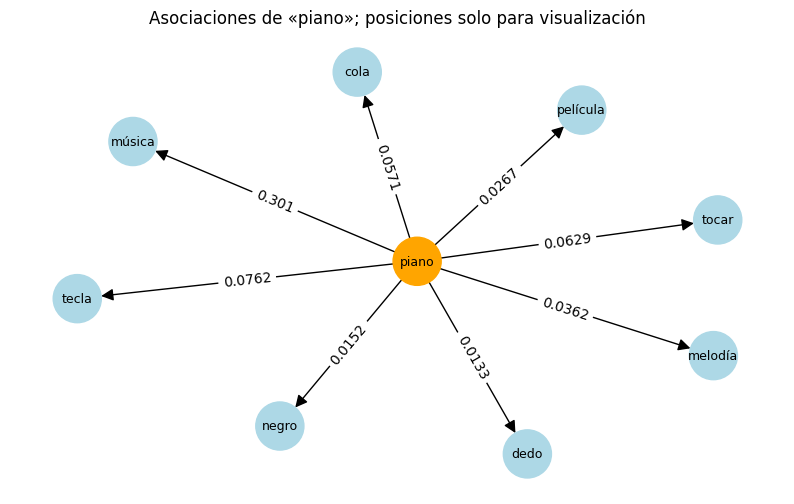

In [ ]:
# construir grafo a partir de las asociaciones normalizadas
grafo, asociaciones, colisiones_nalc, excluidas_nalc = construir_grafo(asociaciones_normalizadas)

# todas las palabras que pueden ser candidatas
vocabulario = set(grafo)

# número máximo de palabras en una expresión
MAX_PALABRAS = max((n.count("_") + 1 for n in vocabulario), default=1)

print("Palabras del grafo:", grafo.number_of_nodes())
print("Aristas del grafo:", grafo.number_of_edges())
print("Registros con colisiones:", len(colisiones_nalc))
print("Registros NALC retirados:", len(excluidas_nalc))

dibujar_vecindad(grafo, "piano")


### Ponderaciones de distancia

In [ ]:
# pagerank toma la FSG como fuerza, pero ahora queremos caminos más cortos, hacemos:
# dist_inversa = 1/FSG
# dist_log = -ln(FSG) + 10^-6


# para ver esas dos dist, añade esos "costos" según el FSG
def calcular_distancias(grafo, epsilon=1e-6):
    for _, _, datos in grafo.edges(data=True):
        fuerza = datos["FSG"]
        datos["dist_inversa"] = 1.0 / fuerza
        datos["dist_log"] = -np.log(fuerza) + epsilon
    return grafo

calcular_distancias(grafo)

# checar (asociación más fuerte debería costar menos)
_, _, ejemplo = next(iter(grafo.edges(data=True)))
print("Ejemplo de arista:", ejemplo)


Ejemplo de arista: {'FSG': 0.04, 'dist_inversa': 25.0, 'dist_log': np.float64(3.2188768248682007)}


### Estadísticas del grafo


In [ ]:
def caracterizar_grafo(grafo):
    if not grafo:
        raise ValueError("El grafo debe tener al menos un nodo.")

    inicio = time.perf_counter()
    n = grafo.number_of_nodes()

    # Una fila por nodo; los aislados también cuentan en los promedios.
    nodos = sorted(grafo.nodes())
    grados = pd.DataFrame({
        "nodo": nodos,
        "entrada": [grafo.in_degree(nodo) for nodo in nodos],
        "salida": [grafo.out_degree(nodo) for nodo in nodos],
    })
    grados["total"] = grados["entrada"] + grados["salida"]

    resumen = {
        "nodos": n,
        "aristas": grafo.number_of_edges(),
        "grado_medio_entrada": grados["entrada"].mean(),
        "grado_medio_salida": grados["salida"].mean(),
        "grado_medio_total": grados["total"].mean(),
    }

    # una fila por componente, ordenadas de mayor a menor
    tablas_componentes = []
    for tipo, grupos in (
        ("debiles", nx.weakly_connected_components(grafo)),
        ("fuertes", nx.strongly_connected_components(grafo)),
    ):
        tamanos = sorted((len(grupo) for grupo in grupos), reverse=True)
        tablas_componentes.append(pd.DataFrame({
            "tipo": tipo,
            "componente": range(1, len(tamanos) + 1),
            "nodos": tamanos,
            "proporcion": [tamano / n for tamano in tamanos],
        }))
        resumen[f"componentes_{tipo}"] = len(tamanos)
        resumen[f"mayor_componente_{tipo}"] = tamanos[0]
    componentes = pd.concat(tablas_componentes, ignore_index=True)

    # distribuciones separadas de grado de entrada, salida y total
    tablas_distribucion = []
    for tipo in ("entrada", "salida", "total"):
        conteos = grados[tipo].value_counts().sort_index().rename_axis("grado").reset_index(name="nodos")
        conteos["tipo"] = tipo
        conteos["proporcion"] = conteos["nodos"] / n
        tablas_distribucion.append(conteos[["tipo", "grado", "nodos", "proporcion"]])
    distribucion = pd.concat(tablas_distribucion, ignore_index=True)

    resumen["agrupamiento_dirigido_sin_peso"] = nx.average_clustering(grafo, weight=None, count_zeros=True)
    resumen["segundos_calculo"] = time.perf_counter() - inicio
    return pd.DataFrame([resumen]), componentes, grados, distribucion


,valor
nodos,12141.000000
aristas,85663.000000
grado_medio_entrada,7.055679
grado_medio_salida,7.055679
grado_medio_total,14.111358
componentes_debiles,1.000000
mayor_componente_debiles,12141.000000
componentes_fuertes,6988.000000
mayor_componente_fuertes,5090.000000
agrupamiento_dirigido_sin_peso,0.105485


Estadísticas guardadas en: /content/gdrive/MyDrive/Proyecto2/salidas_proyecto2_limpio/desarrollo_1000


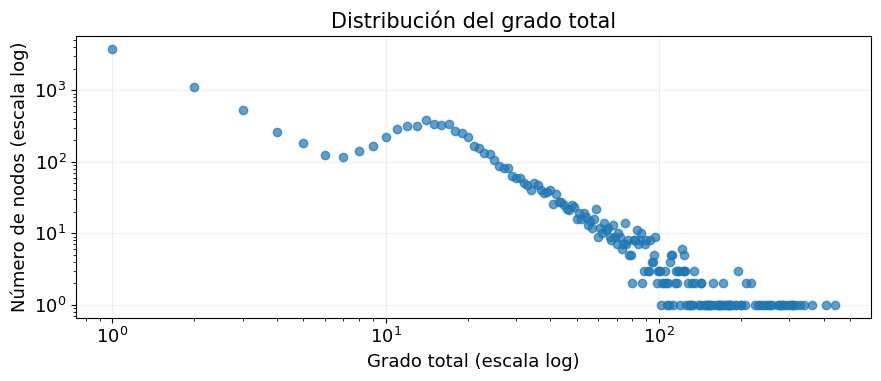

In [ ]:
# se guarda aquí, antes de las búsquedas
estadisticas_grafo, componentes_grafo, grados_por_nodo, distribucion_grado = caracterizar_grafo(grafo)

os.makedirs(CARPETA_SALIDA, exist_ok=True)
estadisticas_grafo.to_csv(f"{CARPETA_SALIDA}/estadisticas_grafo.csv", index=False)
componentes_grafo.to_csv(f"{CARPETA_SALIDA}/componentes_grafo.csv", index=False)
grados_por_nodo.to_csv(f"{CARPETA_SALIDA}/grados_por_nodo.csv", index=False)
distribucion_grado.to_csv(f"{CARPETA_SALIDA}/distribucion_grado.csv", index=False)

display(estadisticas_grafo.T.rename(columns={0: "valor"}))
print("Estadísticas guardadas en:", CARPETA_SALIDA)

plt.rcParams.update({"font.size": 13, "axes.titlesize": 15})

# El grado cero se conserva en los datos, pero no aparece en escala logarítmica.
datos = distribucion_grado.query("tipo == 'total' and grado > 0")

fig, ax = plt.subplots(figsize=(9, 4))
ax.loglog(datos["grado"], datos["nodos"], "o", alpha=0.7)
ax.set(
    title="Distribución del grado total",
    xlabel="Grado total (escala log)",
    ylabel="Número de nodos (escala log)",
)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


### 5. Preparar descripciones

In [ ]:
# concierte el texto ya pasado en spaCy, en lemas, semillas y palabras a excluir

def preparar_descripcion(doc, vocabulario, max_palabras):

    # lista de (lema, es_palabra_funcional) para cada palabra del texto
    unidades = [(normalizar_superficie(t.lemma_ or t.text), t.is_stop) for t in doc if t.is_alpha]

    # buscar todas las expresiones de hasta max_palabras que existan en el grafo
    coincidencias = {}
    excluir = {palabra for palabra, _ in unidades}
    for inicio in range(len(unidades)):
        for longitud in range(1, min(max_palabras, len(unidades) - inicio) + 1):
            etiqueta = "_".join(p for p, _ in unidades[inicio:inicio + longitud])
            if etiqueta in vocabulario:
                excluir.add(etiqueta)
                # una palabra funcional sola no cuenta como lema, pero sí dentro de una expresión
                if longitud > 1 or not unidades[inicio][1]:
                    coincidencias.setdefault(inicio, []).append((longitud, etiqueta))

    # recorrer el texto y tomar la expresión más larga disponible
    lemas = []
    inicio = 0
    while inicio < len(unidades):
        opciones = coincidencias.get(inicio, [])
        if opciones:
            longitud, etiqueta = max(opciones)
            lemas.append(etiqueta)
            inicio += longitud
        else:
            # si no hay expresión, usar la palabra sola
            if not unidades[inicio][1]:
                lemas.append(unidades[inicio][0])
            inicio += 1

    # quitar duplicados y ordenar
    lemas = sorted(set(lemas))
    semillas = sorted(set(lemas) & vocabulario)

    return {
        "lemas": lemas,
        "semillas": semillas,
        "excluir": sorted(excluir),
        "fuera_vocabulario": sorted(set(lemas) - vocabulario),
        "cubierta": bool(semillas),
    }

# indica si el texto tiene la palabra original
def menciona_original(texto, palabra):
    palabra = unicodedata.normalize("NFC", str(palabra)).replace("_", " ").strip().casefold()
    if not palabra:
        return False

    texto = unicodedata.normalize("NFC", str(texto)).casefold()

    # buscar la palabra completa, permite número opcional al final
    patron = r"(?<!\w)" + r"\s+".join(re.escape(p) for p in palabra.split()) + r"\d*(?!\w)"
    return re.search(patron, texto) is not None


# separa preguntas válidas de las excluidas
def preparar_evaluacion(tabla, modelo, vocabulario, max_palabras):
    datos = tabla.copy()

    # vacío significa que la fila sigue siendo válida
    motivos = pd.Series("", index=datos.index)

    # palabra correcta debe existir en el grafo
    fuera = ~datos["word"].isin(vocabulario)
    motivos.loc[fuera] = "objetivo_fuera_del_grafo"
    candidatas = datos.loc[~fuera].copy()

    # detectar repetidos
    candidatas["clave_definicion"] = (
        candidatas["definition"].astype("string")
        .str.normalize("NFC").str.casefold()
        .str.replace(r"\s+", " ", regex=True).str.strip()
    )

    # mismo texto con palabras distintas
    conflictos = candidatas.groupby("clave_definicion")["word"].transform("nunique").gt(1)
    motivos.loc[candidatas.index[conflictos]] = "texto_con_objetivos_distintos"

    # mismo texto para la misma palabra, conservamos la primera
    repetidas = ~conflictos & candidatas.duplicated("clave_definicion", keep="first")
    motivos.loc[candidatas.index[repetidas]] = "texto_repetido_mismo_objetivo"

    # quedarse solo con las filas que no tienen conflicto ni repetición
    candidatas = candidatas.loc[~conflictos & ~repetidas].copy()
    if candidatas.empty:
        raise ValueError("No quedaron definiciones después de los filtros. Revisa los datos y sus reglas.")

    # preparar cada descripción con spaCy, en grupos
    docs = modelo.pipe(candidatas["definition"].astype(str), batch_size=128)
    consultas = [
        preparar_descripcion(doc, vocabulario, max_palabras)
        for doc in tqdm(docs, total=len(candidatas), desc="Preparar descripciones")
    ]
    candidatas = pd.concat([candidatas.reset_index(), pd.DataFrame(consultas)], axis=1).set_index("index")

    # descripción menciona su respuesta
    menciona = [
        objetivo in excluir or menciona_original(texto, original)
        for objetivo, excluir, texto, original in zip(
            candidatas["word"], candidatas["excluir"], candidatas["definition"], candidatas["word_original"]
        )
    ]
    motivos.loc[candidatas.index[menciona]] = "descripcion_contiene_objetivo"

    # filas retiradas, con su motivo
    auditoria = datos.loc[motivos.ne("")].copy()
    auditoria["motivo"] = motivos.loc[auditoria.index]

    # filas que no tienen motivo
    validas = candidatas.loc[motivos.loc[candidatas.index].eq("")].copy()

    # comprobación, que no se perdió ninguna fila
    assert len(datos) == len(validas) + len(auditoria)
    return validas, auditoria


In [ ]:

definiciones, excluidas_evaluacion = preparar_evaluacion(
    definiciones_normalizadas, nlp, vocabulario, MAX_PALABRAS
)

# juntar las dos "auditorías" (retiradas)
auditoria_definiciones = pd.concat([excluidas_formas, excluidas_evaluacion], ignore_index=True)

print("Definiciones evaluables:", len(definiciones))
print("Conceptos distintos:", definiciones["word"].nunique())
print("Cobertura de entrada:", f"{definiciones['cubierta'].mean():.1%}")
display(auditoria_definiciones["motivo"].value_counts().to_frame("filas"))
display(definiciones[["word_original", "word", "definition", "semillas"]].head(5))

if len(definiciones) < 300:
    print("AVISO: todavía no se cumple el mínimo de 300 definiciones evaluables.")


Preparar descripciones:   0%|          | 0/31065 [00:00<?, ?it/s]

Definiciones evaluables: 29188
Conceptos distintos: 8635
Cobertura de entrada: 98.1%


,filas
motivo,
conjugacion,742795
objetivo_fuera_del_grafo,68630
glosa_de_forma,30019
descripcion_contiene_objetivo,1877
texto_con_objetivos_distintos,1427
texto_repetido_mismo_objetivo,48
encabezado_sin_definicion,6


,word_original,word,definition,semillas
index,,,,
958,abalorio,abalorio,Adorno formado por un conjunto de dichas cuent...,"[adorno, conjunto, cordón, cuenta, dicho, hilo]"
959,abalorio,abalorio,Cualquier producto elaborado por la industria ...,"[bisutería, industria, producto]"
960,abalorio,abalorio,"Cuenta de vidrio, madera, piedra, u otro mater...","[adorno, collar, esfera, fabricar, forma, labo..."
1372,abandonado,abandonar,Se dice de algo que se encuentra descuidado o ...,[descuidado]
1373,abandonado,abandonar,Se dice de un lugar que se encuentra desierto ...,"[desierto, lugar]"


### 6. Separar desarrollo y prueba



In [ ]:
#divide los conceptos en dos grupos y asigna todas sus descripciones al mismo grupo
def dividir_definiciones(tabla, semilla, proporcion_desarrollo=0.25):

    #obtiene la lista de los conceptos únicos
    conceptos = sorted(tabla["word"].unique())

    #verifica que se cumpla con el mínimo de 4 conceptos
    if len(conceptos) < 4:
        raise ValueError("Se necesitan al menos cuatro conceptos para esta partición.")

    #reparte los conceptos entre prueba y desarrollo
    desarrollo, prueba = train_test_split(conceptos, train_size=proporcion_desarrollo, random_state=semilla)

    #copia los datos y marca la particion de cada fila
    datos = tabla.copy()
    datos["particion"] = np.where(datos["word"].isin(desarrollo), "desarrollo", "prueba")

    #separa los datos en los dataframes para cada partición
    df_desarrollo = datos.loc[datos["particion"].eq("desarrollo")].copy()
    df_prueba = datos.loc[datos["particion"].eq("prueba")].copy()

    #comprueba que ninguna descripcion aparezca en las dos particiones
    assert set(df_desarrollo["word"]).isdisjoint(df_prueba["word"])
    assert set(df_desarrollo["clave_definicion"]).isdisjoint(df_prueba["clave_definicion"])
    return df_desarrollo, df_prueba


In [ ]:
# separa los datos en dos conjuntos
df_desarrollo, df_prueba = dividir_definiciones(definiciones, SEMILLA)

# ordena por id para que la selección no dependa del orden de las filas y elije una muestra antes de evaluar el modelo
muestra_prueba = (
    df_prueba.sort_values("id")
    .sample(n=N_PRUEBA, random_state=SEMILLA)
    .sort_values("id").copy()
)

# crea la carpeta de salida y guarda los ids de la muestra reservada
os.makedirs(CARPETA_SALIDA, exist_ok=True)
muestra_prueba[["id"]].to_csv(f"{CARPETA_SALIDA}/ids_muestra_prueba.csv", index=False)

print("Definiciones disponibles en la partición de prueba:", len(df_prueba))
display(pd.DataFrame({
    "definiciones": [len(df_desarrollo), len(muestra_prueba)],
    "conceptos": [df_desarrollo["word"].nunique(), muestra_prueba["word"].nunique()],
}, index=["desarrollo", "prueba_final_reservada"]))


Definiciones disponibles en la partición de prueba: 21863


,definiciones,conceptos
desarrollo,7325,2158
prueba_final_reservada,1000,899


### 7. Modelos de búsqueda


In [ ]:
# devuelve las palabras ordenadas por puntuacion
def buscar_pagerank(grafo, consulta, alpha=0.85):
    """Devuelve todas las palabras ordenadas por puntuación, sin las de la descripción."""
    semillas = consulta["semillas"]
    if not semillas:
        return []

    # cada semilla empieza con la misma importancia
    pesos = {palabra: 1 / len(semillas) for palabra in semillas}

    # calcular PageRank
    puntuaciones = nx.pagerank(
        grafo,
        personalization=pesos,
        dangling=pesos,
        weight="FSG",
        alpha=alpha,
        max_iter=1000,
        tol=1e-8,
    )

    # ordenar de mayor a menor puntuación, si empate alfabéticamente
    ordenadas = sorted(puntuaciones, key=lambda palabra: (-puntuaciones[palabra], palabra))

    # no devolver palabras que ya están en la descripción
    excluir = set(consulta["excluir"])
    return [palabra for palabra in ordenadas if palabra not in excluir]


In [ ]:
# ordenar las palabras por costo mínimo de semillas, inversa y log

def buscar_distancia(grafo, consulta, atributo):
    semillas = consulta["semillas"]
    if not semillas:
        return []

    # calcular costo mínimo desde todas las semillas
    # solo sigue aristas en su dirección
    distancias = nx.multi_source_dijkstra_path_length(grafo, semillas, weight=atributo)

    # costo más bajo primero, en empate alfabético.
    ordenadas = sorted(distancias, key=lambda palabra: (distancias[palabra], palabra))

    # no devolver palabras de la propia descripción
    excluir = set(consulta["excluir"])
    return [palabra for palabra in ordenadas if palabra not in excluir]


#### Grado ponderado de entrada (completo y reducido)


In [ ]:
# devolver una vista del subgrafo inducido por semillas y vecinos a un salto
def reducir_grafo(grafo, semillas):
    nodos = set(semillas)
    for semilla in semillas:
        nodos.update(grafo.successors(semilla))
    return grafo.subgraph(nodos)

# ordenar los candidatos de la consulta por fuerza
def buscar_grado_ponderado(grafo, consulta, grados_completos=None):
    if not consulta["semillas"]:
        return []

    subgrafo = reducir_grafo(grafo, consulta["semillas"])
    candidatos = set(subgrafo) - set(consulta["excluir"])

    if grados_completos is None:
        puntuaciones = dict(subgrafo.in_degree(weight="FSG"))
    else:
        puntuaciones = grados_completos

    return sorted(candidatos, key=lambda palabra: (-puntuaciones[palabra], palabra))


In [ ]:
# una sola preparación para la versión completa
inicio = time.perf_counter()
grados_entrada_completos = dict(grafo.in_degree(weight="FSG"))
segundos_grado_completo = time.perf_counter() - inicio


def grado_ponderado_completo(consulta):
    return buscar_grado_ponderado(grafo, consulta, grados_entrada_completos)


def grado_ponderado_reducido(consulta):
    return buscar_grado_ponderado(grafo, consulta)


# reducción y cálculo local se incluyen en el tiempo de búsqueda de cada consulta
configuracion_grado = pd.DataFrame([
    {"modelo": "Grado ponderado completo", "grafo": "completo", "segundos_preparacion": segundos_grado_completo},
    {"modelo": "Grado ponderado reducido", "grafo": "reducido", "segundos_preparacion": 0.0},
])
configuracion_grado["peso"] = "FSG"
configuracion_grado["direccion_grado"] = "entrada"
configuracion_grado["candidatos"] = "vecinos salientes de semillas, un salto; excluir descripcion"
os.makedirs(CARPETA_SALIDA, exist_ok=True)
configuracion_grado.to_csv(f"{CARPETA_SALIDA}/configuracion_grado.csv", index=False)


#### Cercanía entrante: dos distancias, completo y reducido

In [ ]:
# calcula cercanía entrante ponderada con correción WF (equivalente a networkX)
def calcular_cercania(grafo, atributo, lote=128):
    nodos = list(grafo)
    n = len(nodos)
    if n <= 1:
        return dict.fromkeys(nodos, 0.0)

    # buscar quién puede llegar al candidato
    matriz = nx.to_scipy_sparse_array(grafo, nodelist=nodos, weight=atributo, format="csr").T.tocsr()
    puntuaciones = {}
    for inicio in range(0, n, lote):
        fin = min(inicio + lote, n)
        distancias = dijkstra(matriz, directed=True, indices=range(inicio, fin))
        alcanzables = np.isfinite(distancias)
        r = alcanzables.sum(axis=1) - 1  # no contar al propio nodo
        suma_distancias = np.where(alcanzables, distancias, 0.0).sum(axis=1)

        valores = np.zeros(fin - inicio)
        np.divide(r, suma_distancias, out=valores, where=suma_distancias > 0)
        valores *= r / (n - 1)
        puntuaciones.update(zip(nodos[inicio:fin], valores))

    return puntuaciones

# puntuar los mismos candidatos locales que grado ponderado, usando cercanía
def buscar_cercania(grafo, consulta, atributo, puntuaciones_completas=None):
    if not consulta["semillas"]:
        return []

    subgrafo = reducir_grafo(grafo, consulta["semillas"])
    candidatos = set(subgrafo) - set(consulta["excluir"])
    if not candidatos:
        return []

    if puntuaciones_completas is None:
        puntuaciones = calcular_cercania(subgrafo, atributo)
    else:
        puntuaciones = puntuaciones_completas
    return sorted(candidatos, key=lambda palabra: (-puntuaciones[palabra], palabra))


In [ ]:
# 2 precálculos exactos
cercanias_completas = {}
filas_configuracion = []
for etiqueta, atributo in (("1/FSG", "dist_inversa"), ("-log FSG", "dist_log")):
    inicio = time.perf_counter()
    cercanias_completas[atributo] = calcular_cercania(grafo, atributo)
    segundos = time.perf_counter() - inicio
    filas_configuracion.extend([
        {"modelo": f"Cercanía {etiqueta} completo", "grafo": "completo", "distancia": atributo, "segundos_preparacion": segundos},
        {"modelo": f"Cercanía {etiqueta} reducido", "grafo": "reducido", "distancia": atributo, "segundos_preparacion": 0.0},
    ])


def cercania_inversa_completa(consulta):
    return buscar_cercania(grafo, consulta, "dist_inversa", cercanias_completas["dist_inversa"])


def cercania_inversa_reducida(consulta):
    return buscar_cercania(grafo, consulta, "dist_inversa")


def cercania_log_completa(consulta):
    return buscar_cercania(grafo, consulta, "dist_log", cercanias_completas["dist_log"])


def cercania_log_reducida(consulta):
    return buscar_cercania(grafo, consulta, "dist_log")


configuracion_cercania = pd.DataFrame(filas_configuracion)
configuracion_cercania["direccion"] = "entrante"
configuracion_cercania["correccion"] = "Wasserman-Faust"
configuracion_cercania["lote"] = 128
configuracion_cercania["candidatos"] = "vecinos salientes de semillas, un salto; excluir descripcion"
os.makedirs(CARPETA_SALIDA, exist_ok=True)
configuracion_cercania.to_csv(f"{CARPETA_SALIDA}/configuracion_cercania.csv", index=False)
tabla_cercanias = pd.DataFrame(cercanias_completas).rename(columns={
    "dist_inversa": "cercania_inversa", "dist_log": "cercania_log",
})
tabla_cercanias.rename_axis("nodo").reset_index().to_csv(
    f"{CARPETA_SALIDA}/puntuaciones_cercania_completa.csv", index=False
)


#### Intermediación



In [ ]:
# intermediación dirigida normalizada
def calcular_intermediacion(grafo, atributo, k=64, semilla=1950):
    # copia pequeña para evitar recorrer repetidamente los filtros de una vista de subgrafo
    trabajo = grafo.copy()
    muestra = k if len(trabajo) > k else None
    return nx.betweenness_centrality(
        trabajo, k=muestra, normalized=True, weight=atributo, seed=semilla,
    )

# ordenar los candidatos locales por intermediación completa o reducida
def buscar_intermediacion(grafo, consulta, atributo, puntuaciones_completas=None, k=16, semilla=1950):
    if not consulta["semillas"]:
        return []
    subgrafo = reducir_grafo(grafo, consulta["semillas"])
    candidatos = set(subgrafo) - set(consulta["excluir"])
    if not candidatos:
        return []
    if puntuaciones_completas is None:
        puntuaciones = calcular_intermediacion(subgrafo, atributo, k, semilla)
    else:
        puntuaciones = puntuaciones_completas
    return sorted(candidatos, key=lambda palabra: (-puntuaciones[palabra], palabra))

In [ ]:
K_INTERMEDIACION_COMPLETA = 64
K_INTERMEDIACION_REDUCIDA = 16
intermediaciones_completas = {}
filas_intermediacion = []
for etiqueta, atributo in (("1/FSG", "dist_inversa"), ("-log FSG", "dist_log")):
    inicio = time.perf_counter()
    intermediaciones_completas[atributo] = calcular_intermediacion(
        grafo, atributo, K_INTERMEDIACION_COMPLETA, SEMILLA,
    )
    segundos = time.perf_counter() - inicio
    filas_intermediacion.extend([
        {"modelo": f"Intermediación {etiqueta} completo", "grafo": "completo", "distancia": atributo,
         "k_maximo": K_INTERMEDIACION_COMPLETA, "segundos_preparacion": segundos},
        {"modelo": f"Intermediación {etiqueta} reducido", "grafo": "reducido", "distancia": atributo,
         "k_maximo": K_INTERMEDIACION_REDUCIDA, "segundos_preparacion": 0.0},
    ])


def intermediacion_inversa_completa(consulta):
    return buscar_intermediacion(grafo, consulta, "dist_inversa", intermediaciones_completas["dist_inversa"])


def intermediacion_inversa_reducida(consulta):
    return buscar_intermediacion(grafo, consulta, "dist_inversa", k=K_INTERMEDIACION_REDUCIDA, semilla=SEMILLA)


def intermediacion_log_completa(consulta):
    return buscar_intermediacion(grafo, consulta, "dist_log", intermediaciones_completas["dist_log"])


def intermediacion_log_reducida(consulta):
    return buscar_intermediacion(grafo, consulta, "dist_log", k=K_INTERMEDIACION_REDUCIDA, semilla=SEMILLA)


configuracion_intermediacion = pd.DataFrame(filas_intermediacion)
configuracion_intermediacion["semilla"] = SEMILLA
configuracion_intermediacion["normalizada"] = True
configuracion_intermediacion["candidatos"] = "vecinos salientes de semillas, un salto; excluir descripcion"
os.makedirs(CARPETA_SALIDA, exist_ok=True)
configuracion_intermediacion.to_csv(f"{CARPETA_SALIDA}/configuracion_intermediacion.csv", index=False)
pd.DataFrame(intermediaciones_completas).rename(columns={
    "dist_inversa": "intermediacion_inversa", "dist_log": "intermediacion_log",
}).rename_axis("nodo").reset_index().to_csv(
    f"{CARPETA_SALIDA}/puntuaciones_intermediacion_completa.csv", index=False,
)

#### node2vec, tres configuraciones y suma de vectores


In [ ]:
# distribución sobre salientes, FSG multiplicada
def probabilidades_node2vec(grafo, actual, anterior=None, p=1.0, q=1.0):
    if not (np.isfinite(p) and np.isfinite(q) and p > 0 and q > 0):
        raise ValueError("p y q deben ser positivos y finitos.")
    vecinos = sorted(grafo.successors(actual))
    if not vecinos:
        return vecinos, np.array([], dtype=float)
    pesos = np.array([grafo[actual][vecino]["FSG"] for vecino in vecinos], dtype=float)
    if anterior is not None:
        pesos *= [1 / p if vecino == anterior else 1.0 if grafo.has_edge(anterior, vecino) else 1 / q
                  for vecino in vecinos]
    return vecinos, pesos / pesos.sum()

# generar caminatas reproducibles
def generar_caminatas_node2vec(grafo, longitud, caminatas, p, q, semilla):
    if longitud < 1 or caminatas < 1:
        raise ValueError("La longitud y el número de caminatas deben ser positivos.")
    if not (np.isfinite(p) and np.isfinite(q) and p > 0 and q > 0):
        raise ValueError("p y q deben ser positivos y finitos.")
    rng = np.random.default_rng(semilla)
    nodos = sorted(grafo)
    cache = {}
    recorridos = []
    for _ in range(caminatas):
        for inicio in rng.permutation(nodos):
            camino = [str(inicio)]
            while len(camino) < longitud:
                actual = camino[-1]
                anterior = camino[-2] if len(camino) > 1 else None
                clave = (anterior, actual)
                if clave not in cache:
                    cache[clave] = probabilidades_node2vec(grafo, actual, anterior, p, q)
                vecinos, probabilidades = cache[clave]
                if not vecinos:
                    break
                camino.append(vecinos[int(rng.choice(len(vecinos), p=probabilidades))])
            recorridos.append(camino)
    return recorridos

# para no depender del hash aleatorio
def hash_estable(texto):
    return zlib.crc32(texto.encode("utf-8"))

# prepara índices y vectores unitarios para buscar por coseno
def preparar_vectores(nodos, vectores):
    matriz = np.asarray(vectores, dtype=np.float64)
    normas = np.linalg.norm(matriz, axis=1, keepdims=True)
    unitarios = np.divide(matriz, normas, out=np.zeros_like(matriz), where=normas > 0)
    return {"nodos": list(nodos), "indice": {n: i for i, n in enumerate(nodos)},
            "vectores": matriz, "unitarios": unitarios}

# skip-gram sobre caminatas NALC, vectores y sus tiempos
def entrenar_node2vec(grafo, configuracion, semilla):
    inicio = time.perf_counter()
    recorridos = generar_caminatas_node2vec(
        grafo, configuracion["longitud"], configuracion["caminatas"],
        configuracion["p"], configuracion["q"], semilla,
    )
    segundos_caminatas = time.perf_counter() - inicio
    inicio = time.perf_counter()
    modelo = Word2Vec(
        sentences=recorridos, vector_size=configuracion["dimension"], window=5,
        min_count=1, sg=1, negative=5, sample=0, epochs=5,
        workers=1, seed=semilla, sorted_vocab=1, hashfxn=hash_estable,
    )
    segundos_entrenamiento = time.perf_counter() - inicio
    nodos = sorted(modelo.wv.index_to_key)
    datos = preparar_vectores(nodos, np.vstack([modelo.wv[nodo] for nodo in nodos]))
    datos["segundos_caminatas"] = segundos_caminatas
    datos["segundos_entrenamiento"] = segundos_entrenamiento
    return datos

# cargar los vectores congelados, sin volver a entrenar
def cargar_node2vec(ruta):
    with np.load(ruta, allow_pickle=False) as archivo:
        return preparar_vectores(archivo["nodos"].tolist(), archivo["vectores"])

# sumar los vectores de las semillas y ordenar por coseno
def buscar_node2vec(vectores, consulta):
    indices = [vectores["indice"][p] for p in consulta["semillas"] if p in vectores["indice"]]
    if not indices:
        return []
    suma = vectores["vectores"][indices].sum(axis=0)
    norma = np.linalg.norm(suma)
    if norma == 0:
        return []
    similitudes = np.einsum("ij,j->i", vectores["unitarios"], suma / norma)
    # Los nodos están ordenados alfabéticamente; el orden estable resuelve empates.
    orden = np.argsort(-similitudes, kind="stable")
    excluir = set(consulta["excluir"])
    return [vectores["nodos"][i] for i in orden if vectores["nodos"][i] not in excluir]

In [ ]:
CONFIGURACIONES_NODE2VEC = [
    {"nombre": "local64", "dimension": 64, "p": 1.0, "q": 2.0, "longitud": 20, "caminatas": 4},
    {"nombre": "neutral64", "dimension": 64, "p": 1.0, "q": 1.0, "longitud": 20, "caminatas": 4},
    {"nombre": "explorador64", "dimension": 64, "p": 2.0, "q": 0.5, "longitud": 20, "caminatas": 4},
]
VECTORES_NODE2VEC = {}
filas_node2vec = []
os.makedirs(f"{CARPETA_SALIDA}/vectores", exist_ok=True)
for configuracion in CONFIGURACIONES_NODE2VEC:
    nombre = configuracion["nombre"]
    datos = entrenar_node2vec(grafo, configuracion, SEMILLA)
    VECTORES_NODE2VEC[nombre] = datos
    np.savez_compressed(f"{CARPETA_SALIDA}/vectores/{nombre}.npz",
                        nodos=np.array(datos["nodos"]), vectores=datos["vectores"])
    filas_node2vec.append({
        **configuracion, "modelo": f"node2vec {nombre}", "semilla": SEMILLA,
        "ventana": 5, "epocas": 5, "workers": 1, "sg": 1, "negative": 5, "sample": 0,
        "segundos_caminatas": datos["segundos_caminatas"],
        "segundos_entrenamiento": datos["segundos_entrenamiento"],
    })
    print("Entrenado:", nombre)
configuracion_node2vec = pd.DataFrame(filas_node2vec)
configuracion_node2vec.to_csv(f"{CARPETA_SALIDA}/configuracion_node2vec.csv", index=False)


def node2vec_local(consulta):
    return buscar_node2vec(VECTORES_NODE2VEC["local64"], consulta)


def node2vec_neutral(consulta):
    return buscar_node2vec(VECTORES_NODE2VEC["neutral64"], consulta)


def node2vec_explorador(consulta):
    return buscar_node2vec(VECTORES_NODE2VEC["explorador64"], consulta)

Entrenado: local64
Entrenado: neutral64
Entrenado: explorador64


In [ ]:
# probar búsqueda con descripción escrita a manita
DESCRIPCION = "Instrumento musical con teclas que se toca con las manos."

consulta = preparar_descripcion(nlp(DESCRIPCION), vocabulario, MAX_PALABRAS)
ranking = buscar_pagerank(grafo, consulta, ALPHA)

print("Semillas:", consulta["semillas"])
print("Fuera del grafo:", consulta["fuera_vocabulario"])
display(pd.DataFrame({"posicion": range(1, min(5, len(ranking)) + 1), "palabra": ranking[:5]}))


Semillas: ['instrumento', 'mano', 'musical', 'tecla', 'tocar']
Fuera del grafo: []


,posicion,palabra
0,1,música
1,2,ordenador
2,3,piano
3,4,guitarra
4,5,teatro


### 8. Evaluar


In [ ]:
# calcular la posición de la respuesta correcta y sus medidas de acierto

def metricas_ranking(objetivo, ranking):
    posicion = ranking.index(objetivo) + 1 if objetivo in ranking else None
    return {
        "posicion": posicion,
        **{f"p@{k}": int(posicion is not None and posicion <= k) for k in (1, 3, 5)},
        "RR": 1 / posicion if posicion is not None else 0.0,
    }

# ejecutar un modelo sobre cada consulta y compara su rankig con respuesta correcta
# buscar_fn -> recibe semillas y palabras a excluir

def evaluar(buscar_fn, datos, nombre="modelo"):
    if datos.empty:
        raise ValueError("No hay descripciones para evaluar.")

    filas = []
    for fila in tqdm(datos.itertuples(index=False), total=len(datos), desc=f"Evaluar {nombre}"):
        consulta = {"semillas": fila.semillas, "excluir": fila.excluir}

        # medir solo la búsqueda, sin contar la preparación con spaCy
        inicio = time.perf_counter()
        ranking = buscar_fn(consulta)
        tiempo_ms = (time.perf_counter() - inicio) * 1000

        # ranking con repetidos cambiaría posiciones, se detiene mejor
        assert isinstance(ranking, list) and len(ranking) == len(set(ranking)), \
            "buscar_fn debe devolver una lista sin palabras repetidas"

        filas.append({
            "id": fila.id,
            "word_original": fila.word_original,
            "word": fila.word,
            "definition": fila.definition,
            "classification": fila.classification,
            "fuente": fila.fuente,
            "semillas": fila.semillas,
            "excluir": fila.excluir,
            "fuera_vocabulario": fila.fuera_vocabulario,
            "cubierta": fila.cubierta,
            "lemas_utiles": len(fila.semillas),
            "top5": ranking[:5],
            "consulta_ms": tiempo_ms,
            **metricas_ranking(fila.word, ranking),
        })

    detalle = pd.DataFrame(filas)

    # promedios de las medidas para el resumen del modelo.
    resumen = detalle[
        ["p@1", "p@3", "p@5", "RR", "cubierta", "lemas_utiles", "consulta_ms"]
    ].mean()
    resumen = resumen.rename({
        "RR": "MRR",
        "cubierta": "cobertura",
        "lemas_utiles": "lemas_utiles_promedio",
        "consulta_ms": "consulta_ms_promedio",
    })
    resumen["n"] = len(detalle)
    resumen["modelo"] = nombre
    return detalle, resumen


Evaluar PageRank:   0%|          | 0/1000 [00:00<?, ?it/s]

Evaluar Distancia 1/FSG:   0%|          | 0/1000 [00:00<?, ?it/s]

Evaluar Distancia -log FSG:   0%|          | 0/1000 [00:00<?, ?it/s]

Evaluar Grado ponderado completo:   0%|          | 0/1000 [00:00<?, ?it/s]

Evaluar Grado ponderado reducido:   0%|          | 0/1000 [00:00<?, ?it/s]

Evaluar Cercanía 1/FSG completo:   0%|          | 0/1000 [00:00<?, ?it/s]

... (7 outputs left out)

Evaluar node2vec local64:   0%|          | 0/1000 [00:00<?, ?it/s]

Evaluar node2vec neutral64:   0%|          | 0/1000 [00:00<?, ?it/s]

Evaluar node2vec explorador64:   0%|          | 0/1000 [00:00<?, ?it/s]

,p@1,p@3,p@5,MRR,cobertura,lemas_utiles_promedio,consulta_ms_promedio,n
modelo,,,,,,,,
PageRank,0.010,0.020,0.032,0.023457,0.985,4.643,224.357776,1000.0
Distancia 1/FSG,0.009,0.023,0.030,0.022059,0.985,4.643,90.741972,1000.0
Distancia -log FSG,0.009,0.025,0.035,0.025576,0.985,4.643,104.110362,1000.0
Grado ponderado completo,0.000,0.004,0.005,0.008560,0.985,4.643,0.162080,1000.0
Grado ponderado reducido,0.007,0.013,0.019,0.017852,0.985,4.643,3.105447,1000.0
Cercanía 1/FSG completo,0.001,0.004,0.010,0.009628,0.985,4.643,0.121026,1000.0
Cercanía 1/FSG reducido,0.003,0.008,0.014,0.013372,0.985,4.643,2.897339,1000.0
Cercanía -log FSG completo,0.001,0.002,0.009,0.008783,0.985,4.643,0.128535,1000.0
Cercanía -log FSG reducido,0.003,0.011,0.015,0.014293,0.985,4.643,2.755480,1000.0


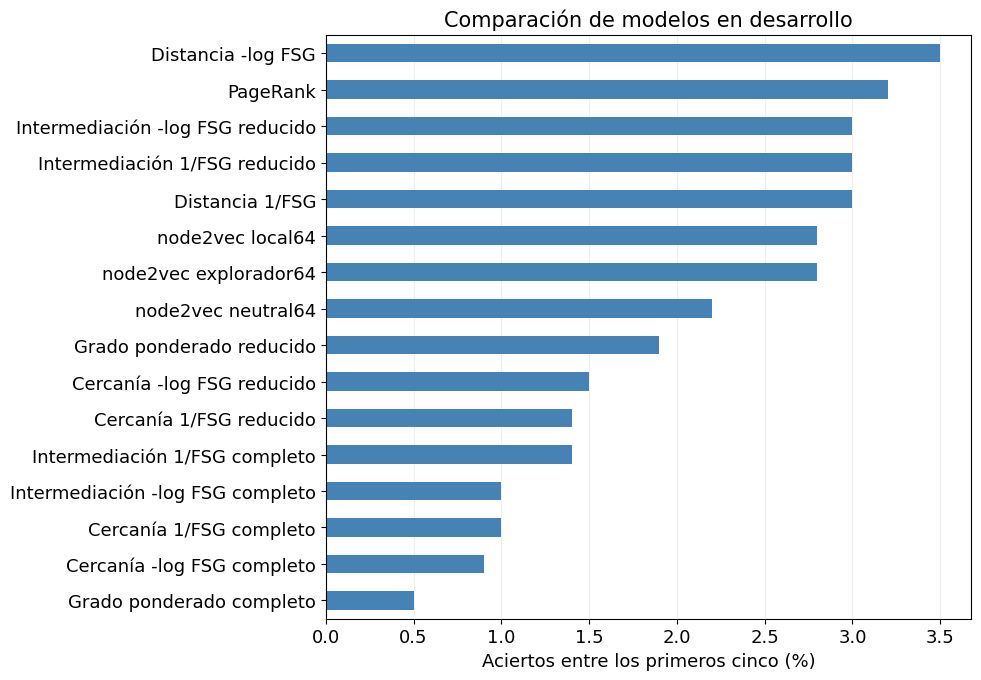

In [ ]:
# muestra fija para todos los modelos, elegida sin consultar sus resultados
muestra = (
    df_desarrollo.copy() if MAX_DESARROLLO is None
    else df_desarrollo.sort_values("id")
    .sample(n=min(MAX_DESARROLLO, len(df_desarrollo)), random_state=SEMILLA)
    .sort_values("id").copy()
)
os.makedirs(CARPETA_SALIDA, exist_ok=True)
muestra[["id"]].to_csv(f"{CARPETA_SALIDA}/ids_muestra_desarrollo.csv", index=False)


# cada modelo tiene la misma forma: consulta -> lista ordenada
def nombre_archivo(texto):
    """Convierte el nombre de un modelo en un nombre de archivo sin espacios ni símbolos."""
    ascii_texto = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", "_", ascii_texto.lower()).strip("_")


def pagerank_base(consulta):
    return buscar_pagerank(grafo, consulta, ALPHA)


def distancia_inversa(consulta):
    return buscar_distancia(grafo, consulta, "dist_inversa")


def distancia_log(consulta):
    return buscar_distancia(grafo, consulta, "dist_log")


MODELOS = {
    "PageRank": pagerank_base,
    "Distancia 1/FSG": distancia_inversa,
    "Distancia -log FSG": distancia_log,
    "Grado ponderado completo": grado_ponderado_completo,
    "Grado ponderado reducido": grado_ponderado_reducido,
    "Cercanía 1/FSG completo": cercania_inversa_completa,
    "Cercanía 1/FSG reducido": cercania_inversa_reducida,
    "Cercanía -log FSG completo": cercania_log_completa,
    "Cercanía -log FSG reducido": cercania_log_reducida,
    "Intermediación 1/FSG completo": intermediacion_inversa_completa,
    "Intermediación 1/FSG reducido": intermediacion_inversa_reducida,
    "Intermediación -log FSG completo": intermediacion_log_completa,
    "Intermediación -log FSG reducido": intermediacion_log_reducida,
    "node2vec local64": node2vec_local,
    "node2vec neutral64": node2vec_neutral,
    "node2vec explorador64": node2vec_explorador,
}

# evaluar cada modelo con la misma muestra
os.makedirs(f"{CARPETA_SALIDA}/modelos", exist_ok=True)
DETALLES = {}
RESUMENES = []
for nombre, buscar_fn in MODELOS.items():
    detalle, resumen = evaluar(buscar_fn, muestra, nombre)
    DETALLES[nombre] = detalle
    RESUMENES.append(resumen)

    # guardar cada modelo al terminar, sin esperar siguientes
    detalle.to_json(
        f"{CARPETA_SALIDA}/modelos/{nombre_archivo(nombre)}.jsonl",
        orient="records", lines=True, force_ascii=False,
    )
    pd.DataFrame(RESUMENES).set_index("modelo").to_csv(f"{CARPETA_SALIDA}/tabla_modelos.csv")

TABLA_MODELOS = pd.DataFrame(RESUMENES).set_index("modelo")
display(TABLA_MODELOS)

datos = TABLA_MODELOS.sort_values("p@5")

ax = (100 * datos["p@5"]).plot.barh(
    figsize=(10, 7),
    color="steelblue",
)
ax.set(
    title="Comparación de modelos en desarrollo",
    xlabel="Aciertos entre los primeros cinco (%)",
    ylabel="",
)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


#### Elegir la ponderación de distancia


In [ ]:
PONDERACIONES = ["Distancia 1/FSG", "Distancia -log FSG"]

MEJOR_PONDERACION = (
    TABLA_MODELOS.loc[PONDERACIONES]
    .sort_values(["MRR", "p@1"], ascending=False)
    .index[0]
)
ATRIBUTOS_DISTANCIA = {
    "Distancia 1/FSG": "dist_inversa",
    "Distancia -log FSG": "dist_log",
}
MEJOR_ATRIBUTO_DISTANCIA = ATRIBUTOS_DISTANCIA[MEJOR_PONDERACION]

# conservar fórmulas y elección para análisis final
tabla_ponderaciones = pd.DataFrame([
    {"modelo": "Distancia 1/FSG", "atributo": "dist_inversa", "formula": "1/FSG"},
    {"modelo": "Distancia -log FSG", "atributo": "dist_log", "formula": "-ln(FSG)+1e-6"},
])
tabla_ponderaciones["seleccionada"] = tabla_ponderaciones["modelo"].eq(MEJOR_PONDERACION)
tabla_ponderaciones.to_csv(f"{CARPETA_SALIDA}/ponderaciones.csv", index=False)

print("Mejor ponderación para distancia mínima en desarrollo:", MEJOR_PONDERACION)
display(TABLA_MODELOS.loc[PONDERACIONES, ["p@1", "p@3", "p@5", "MRR"]])


Mejor ponderación para distancia mínima en desarrollo: Distancia -log FSG


,p@1,p@3,p@5,MRR
modelo,,,,
Distancia 1/FSG,0.009,0.023,0.030,0.022059
Distancia -log FSG,0.009,0.025,0.035,0.025576


### 9. Revisar errores y guardar resultados


In [ ]:
# consultas donde la respuesta no aparece en las primeras 5
def obtener_errores(detalle, limite=15):
    fallos = detalle.loc[detalle["p@5"].eq(0)].head(limite).copy()

    # columnas vacías para escribir la causa
    return fallos.assign(causa_manual="", notas="")


In [ ]:
# modelo con mejor MRR en desarrollo
MEJOR_MODELO = TABLA_MODELOS["MRR"].idxmax()
errores = obtener_errores(DETALLES[MEJOR_MODELO])
print("Modelo para revisar errores:", MEJOR_MODELO)
print("Casos para revisión manual:", len(errores))
display(errores[["word_original", "word", "definition", "classification", "top5", "causa_manual"]])

os.makedirs(CARPETA_SALIDA, exist_ok=True)


# tabla con todos los modelos
resultados_largos = pd.concat(
    [detalle.assign(modelo=nombre) for nombre, detalle in DETALLES.items()],
    ignore_index=True,
)
columnas_graficas = [
    "modelo", "id", "word", "posicion", "p@1", "p@3", "p@5", "RR",
    "cubierta", "lemas_utiles", "consulta_ms",
]
resultados_largos[columnas_graficas].to_csv(f"{CARPETA_SALIDA}/resultados_por_consulta.csv", index=False)

# resumen de los modelos y ponderaciones
TABLA_MODELOS.to_csv(f"{CARPETA_SALIDA}/tabla_modelos.csv")

# tablas de auditoría de los datos
asociaciones.to_csv(f"{CARPETA_SALIDA}/asociaciones_normalizadas.csv", index=False)
colisiones_nalc.to_csv(f"{CARPETA_SALIDA}/colisiones_nalc.csv", index=False)
excluidas_nalc.to_csv(f"{CARPETA_SALIDA}/exclusiones_nalc.csv", index=False)

particiones = pd.concat([df_desarrollo, df_prueba], ignore_index=True)
columnas_def = ["id", "word_original", "word", "definition", "classification", "fuente", "particion"]
particiones[columnas_def].to_csv(f"{CARPETA_SALIDA}/definiciones_y_particiones.csv", index=False)
auditoria_definiciones[["id", "word_original", "classification", "motivo"]].to_csv(
    f"{CARPETA_SALIDA}/auditoria_definiciones.csv", index=False
)
muestra[["id"]].to_csv(f"{CARPETA_SALIDA}/ids_muestra_desarrollo.csv", index=False)
errores.to_json(f"{CARPETA_SALIDA}/errores_revision_manual.jsonl", orient="records", lines=True, force_ascii=False)

print("Resultados guardados en:", CARPETA_SALIDA)


Modelo para revisar errores: Distancia -log FSG
Casos para revisión manual: 15


,word_original,word,definition,classification,top5,causa_manual
0,abalorio,abalorio,Cualquier producto elaborado por la industria ...,sustantivo masculino,"[fábrica, textil, humo, ropa, bruto]",
1,abertura,abertura,"Hendidura, agujero o grieta.",sustantivo femenino,"[negro, hueco, blanco, hoyo, aguja]",
2,abrasador,abrasador,"Que abrasa, que quema.",adjetivo,"[fuego, arder, ropa, calor, dolor]",
3,abrigar,abrigar,Calentar o templar una habitación.,verbo transitivo,"[cuarto, cama, comida, enfriar, dormir]",
4,abrigar,abrigar,Sostener o profesar estas o aquellas ideas; te...,verbo transitivo,"[amor, bombilla, luz, emoción, aguantar]",
5,absoluta,absoluto,Aserción general dicha con tono de seguridad y...,sustantivo femenino,"[hecho, voz, refer, ejército, música]",
6,absoluta,absoluto,"En el ritual católico, ceremonia que tiene efe...",sustantivo femenino,"[boda, viejo, cura, iglesia, recibir]",
7,absoluto,absoluto,"Independiente, con pleno poder, sin restricció...",adjetivo,"[dependiente, solo, tienda, persona, autónomo]",
8,abuelo,abuelo,"En los juegos de azar, ficha o cartón con el n...",sustantivo masculino,"[suerte, caja, cien, matemático, ochenta]",
9,acecho,acecho,Acción o efecto de acechar.,sustantivo masculino,"[causa, película, invernadero, reacción, cine]",


Resultados guardados en: /content/gdrive/MyDrive/Proyecto2/salidas_proyecto2_limpio/desarrollo_1000


### 10. Evaluar prueba

In [ ]:
# seleccionar variante por familia
def seleccionar_modelos(tabla, familias):
    elegidos = []
    for familia, nombres in familias.items():
        candidatas = tabla.loc[nombres].rename_axis("modelo").reset_index()
        ganadora = candidatas.sort_values(
            ["MRR", "p@1", "modelo"], ascending=[False, False, True], kind="stable",
        ).iloc[0]
        elegidos.append({
            "familia": familia, "modelo": ganadora["modelo"],
            "MRR_desarrollo": ganadora["MRR"], "p@1_desarrollo": ganadora["p@1"],
        })
    return pd.DataFrame(elegidos)

Prueba ya evaluada: se conservan la tabla y la selección guardadas, sin volver a ajustar.


,p@1,p@3,p@5,MRR,cobertura,lemas_utiles_promedio,consulta_ms_promedio,n
modelo,,,,,,,,
PageRank,0.008,0.015,0.025,0.020353,0.977,4.394,158.978498,1000.0
Distancia -log FSG,0.007,0.020,0.028,0.022557,0.977,4.394,71.057201,1000.0
Grado ponderado reducido,0.002,0.010,0.022,0.015208,0.977,4.394,1.254553,1000.0
Cercanía -log FSG reducido,0.003,0.010,0.016,0.013315,0.977,4.394,1.765497,1000.0
Intermediación 1/FSG reducido,0.006,0.021,0.029,0.020798,0.977,4.394,3.960791,1000.0
node2vec local64,0.007,0.010,0.012,0.013048,0.977,4.394,4.545543,1000.0


Resultados finales guardados en: /content/gdrive/MyDrive/Proyecto2/salidas_proyecto2_limpio/prueba_1000


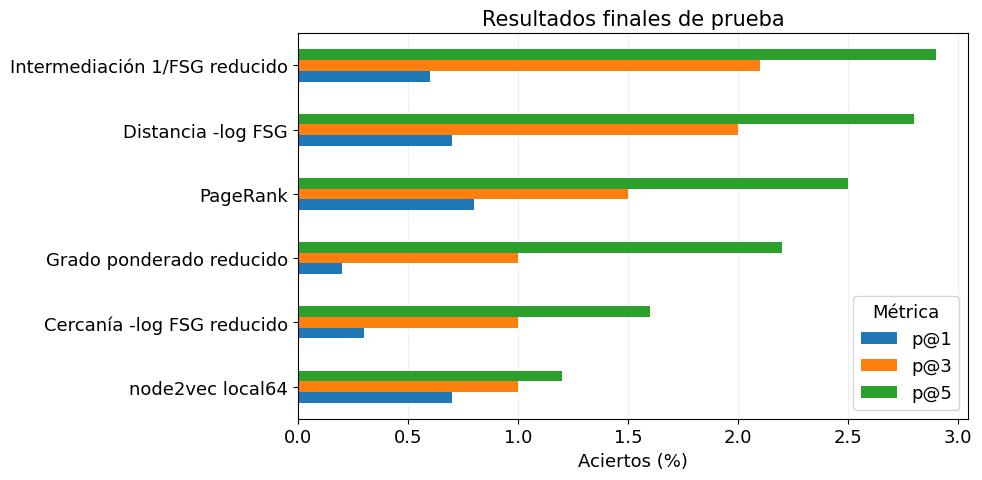

In [ ]:
FAMILIAS = {
    "PageRank": ["PageRank"],
    "Distancia mínima": [n for n in MODELOS if n.startswith("Distancia ")],
    "Grado ponderado": [n for n in MODELOS if n.startswith("Grado ponderado ")],
    "Cercanía": [n for n in MODELOS if n.startswith("Cercanía ")],
    "Intermediación": [n for n in MODELOS if n.startswith("Intermediación ")],
    "node2vec": [n for n in MODELOS if n.startswith("node2vec ")],
}
SELECCION = seleccionar_modelos(TABLA_MODELOS, FAMILIAS)
SELECCION.to_csv(f"{CARPETA_SALIDA}/seleccion_desarrollo.csv", index=False)
CARPETA_PRUEBA = os.path.join(os.path.dirname(CARPETA_SALIDA), "prueba_1000")
archivo_tabla_prueba = f"{CARPETA_PRUEBA}/tabla_modelos.csv"

if os.path.exists(archivo_tabla_prueba):
    print("Prueba ya evaluada: se conservan la tabla y la selección guardadas, sin volver a ajustar.")
    TABLA_PRUEBA = pd.read_csv(archivo_tabla_prueba, index_col="modelo")
else:
    os.makedirs(f"{CARPETA_PRUEBA}/modelos", exist_ok=True)
    # Congelar la selección y los parámetros antes de consultar los resultados de prueba.
    SELECCION.to_csv(f"{CARPETA_PRUEBA}/seleccion_desarrollo.csv", index=False)
    muestra_prueba[["id"]].to_csv(f"{CARPETA_PRUEBA}/ids_muestra_prueba.csv", index=False)
    for archivo in ("configuracion_grado.csv", "configuracion_cercania.csv",
                    "configuracion_intermediacion.csv", "configuracion_node2vec.csv", "ponderaciones.csv"):
        shutil.copyfile(f"{CARPETA_SALIDA}/{archivo}", f"{CARPETA_PRUEBA}/{archivo}")

    DETALLES_PRUEBA = {}
    resumenes_prueba = []
    for fila in SELECCION.itertuples(index=False):
        detalle, resumen = evaluar(MODELOS[fila.modelo], muestra_prueba, fila.modelo)
        detalle.to_json(f"{CARPETA_PRUEBA}/modelos/{nombre_archivo(fila.modelo)}.jsonl",
                        orient="records", lines=True, force_ascii=False)
        DETALLES_PRUEBA[fila.modelo] = detalle
        resumenes_prueba.append(resumen)

    TABLA_PRUEBA = pd.DataFrame(resumenes_prueba).set_index("modelo")
    TABLA_PRUEBA.to_csv(archivo_tabla_prueba)
    resultados_prueba = pd.concat(
        [d.assign(modelo=n) for n, d in DETALLES_PRUEBA.items()], ignore_index=True,
    )
    resultados_prueba[columnas_graficas].to_csv(f"{CARPETA_PRUEBA}/resultados_por_consulta.csv", index=False)

    modelo_principal = SELECCION.sort_values(
        ["MRR_desarrollo", "p@1_desarrollo", "modelo"], ascending=[False, False, True],
    ).iloc[0]["modelo"]
    obtener_errores(DETALLES_PRUEBA[modelo_principal]).to_json(
        f"{CARPETA_PRUEBA}/errores_revision_manual.jsonl", orient="records", lines=True, force_ascii=False,
    )

# una sola tabla, con partición explícita para no mezclar desarrollo y prueba
tabla_comparativa = pd.concat([
    TABLA_MODELOS.rename_axis("modelo").reset_index().assign(particion="desarrollo"),
    TABLA_PRUEBA.rename_axis("modelo").reset_index().assign(particion="prueba"),
], ignore_index=True)
familia_por_modelo = {n: familia for familia, nombres in FAMILIAS.items() for n in nombres}
tabla_comparativa["familia"] = tabla_comparativa["modelo"].map(familia_por_modelo)
tabla_comparativa.to_csv(os.path.join(os.path.dirname(CARPETA_SALIDA), "tabla_comparativa.csv"), index=False)

display(TABLA_PRUEBA)
print("Resultados finales guardados en:", CARPETA_PRUEBA)

datos = TABLA_PRUEBA[["p@1", "p@3", "p@5"]].sort_values("p@5")

ax = (100 * datos).plot.barh(figsize=(10, 5))
ax.set(
    title="Resultados finales de prueba",
    xlabel="Aciertos (%)",
    ylabel="",
)
ax.legend(title="Métrica")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()
